# 02 EDA 与 RFM 客群分层

**输入**：`data/clean/transactions.parquet`（1,007,913 行）+ `returns.parquet`
**输出**：`data/clean/customers.parquet`（客户级 RFM + 客群标签，供 03 建模用）

分析顺序：
1. 月度 GMV 趋势（⚠️ 剔除不完整的 2011-12）
2. 获客与活跃客户趋势
3. 同期群（cohort）留存热力图
4. 客单价分布（长尾 → 分位数 + 对数轴）
5. 头部商品与退货率
6. RFM 分层：分位数打分 vs K-means（肘部法 + 轮廓系数）对比

> 原则：每张图都要回答一个业务问题，没有解读的图不进报告。

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei"]
plt.rcParams["axes.unicode_minus"] = False

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
CLEAN = ROOT / "data" / "clean"
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

tx = pd.read_parquet(CLEAN / "transactions.parquet")
ret = pd.read_parquet(CLEAN / "returns.parquet")
tx["month"] = tx["InvoiceDate"].dt.to_period("M")
tx["Amount"] = tx["Quantity"] * tx["Price"]
print(f"交易 {len(tx):,} 行，销售额 {tx['Amount'].sum():,.0f} 英镑")
print(f"时间：{tx['InvoiceDate'].min()} ~ {tx['InvoiceDate'].max()}")

交易 1,007,913 行，销售额 20,476,260 英镑
时间：2009-12-01 07:45:00 ~ 2011-12-09 12:50:00


## 1. 月度 GMV 趋势

业务问题：**生意在增长吗？季节性如何？** 2011-12 只有 9 天数据，必须剔除，否则会出现假的“暴跌”。

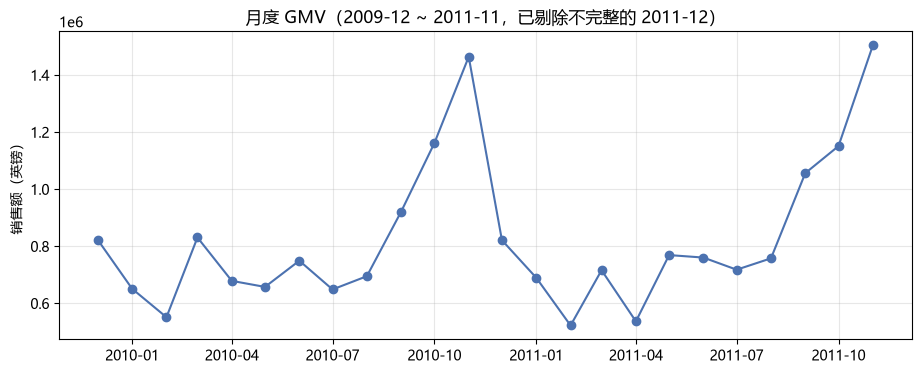

2010 年 1-11 月 GMV：9,011,648；2011 年同期：9,182,868（同比 +1.9%）
峰值月：2011-11（1,503,867）


In [2]:
gmv_m = tx.groupby("month")["Amount"].sum()
gmv_full = gmv_m[gmv_m.index < pd.Period("2011-12")]  # 剔除不完整的 2011-12

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(gmv_full.index.to_timestamp(), gmv_full.values, marker="o", color="#4C72B0")
ax.set_title("月度 GMV（2009-12 ~ 2011-11，已剔除不完整的 2011-12）")
ax.set_ylabel("销售额（英镑）")
ax.grid(alpha=0.3)
fig.savefig(FIG / "01_monthly_gmv.png", dpi=120, bbox_inches="tight")
plt.show()

y2010 = gmv_full[(gmv_full.index >= pd.Period("2010-01")) & (gmv_full.index <= pd.Period("2010-11"))].sum()
y2011 = gmv_full[(gmv_full.index >= pd.Period("2011-01")) & (gmv_full.index <= pd.Period("2011-11"))].sum()
print(f"2010 年 1-11 月 GMV：{y2010:,.0f}；2011 年同期：{y2011:,.0f}（同比 {y2011 / y2010 - 1:+.1%}）")
print(f"峰值月：{gmv_full.idxmax()}（{gmv_full.max():,.0f}）")

## 2. 获客与活跃

业务问题：**增长是靠新客还是老客？** 新客 = 首次购买落在该月的客户。

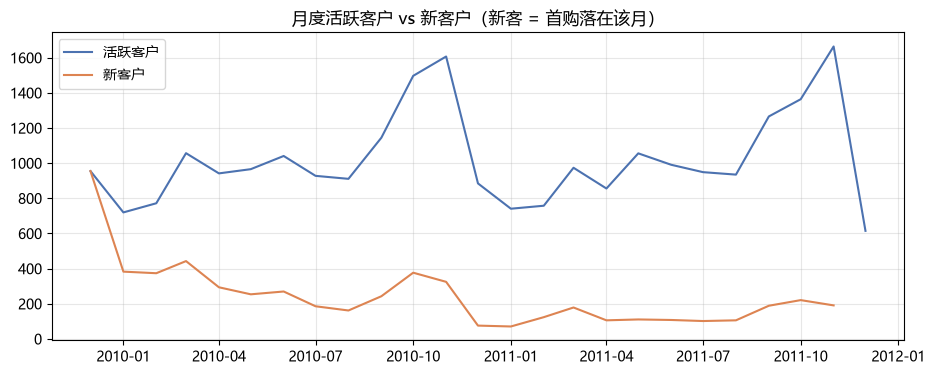

2011-11 老客占比（活跃中非首购者）：88.5%
2010 全年新客：3,387；2011 1-11 月新客：1,508


In [3]:
cust_tx = tx[tx["has_customer"]]
first_month = cust_tx.groupby("Customer_ID")["month"].min().rename("first_month")
active = cust_tx.groupby("month")["Customer_ID"].nunique().rename("活跃客户")
new_cust = first_month[first_month < pd.Period("2011-12")].value_counts().sort_index().rename("新客户")

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(active.index.to_timestamp(), active.values, label="活跃客户", color="#4C72B0")
ax.plot(new_cust.index.to_timestamp(), new_cust.values, label="新客户", color="#DD8452")
ax.set_title("月度活跃客户 vs 新客户（新客 = 首购落在该月）")
ax.legend(); ax.grid(alpha=0.3)
fig.savefig(FIG / "02_active_new.png", dpi=120, bbox_inches="tight")
plt.show()

old_ratio = (active - new_cust.reindex(active.index, fill_value=0)) / active
print(f"2011-11 老客占比（活跃中非首购者）：{old_ratio.loc[pd.Period('2011-11')]:.1%}")
print(f"2010 全年新客：{new_cust[(new_cust.index >= pd.Period('2010-01')) & (new_cust.index <= pd.Period('2010-12'))].sum():,}；"
      f"2011 1-11 月新客：{new_cust[(new_cust.index >= pd.Period('2011-01')) & (new_cust.index <= pd.Period('2011-11'))].sum():,}")

## 3. 同期群留存

业务问题：**不同时期获取的客户，粘性有变化吗？** 行 = 首购月份（同期群），列 = 首购后第 N 个月仍活跃的客户占比。

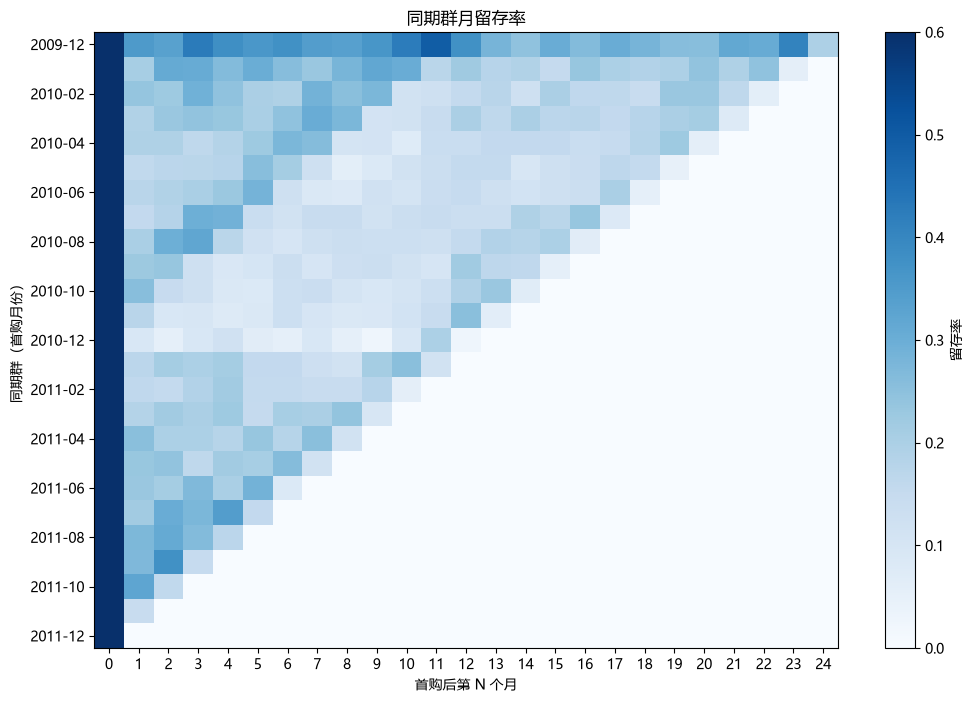

整体复购率（购买月份 >1 的客户占比）：69.8%
各同期群首购次月平均留存率：21.2%


In [4]:
cm = cust_tx[["Customer_ID", "month"]].drop_duplicates().merge(first_month, on="Customer_ID")
cm["n"] = (cm["month"] - cm["first_month"]).apply(lambda x: x.n)
cohort = cm.pivot_table(index="first_month", columns="n", values="Customer_ID", aggfunc="nunique")
size = cohort[0]
retention = cohort.div(size, axis=0)

fig, ax = plt.subplots(figsize=(12, 8))
im = ax.imshow(retention.fillna(0).values, cmap="Blues", aspect="auto", vmax=0.6)
ax.set_xticks(range(len(retention.columns)), retention.columns)
step = max(1, len(retention.index) // 12)
ax.set_yticks(range(0, len(retention.index), step), [str(m) for m in retention.index[::step]])
ax.set_xlabel("首购后第 N 个月")
ax.set_ylabel("同期群（首购月份）")
ax.set_title("同期群月留存率")
fig.colorbar(im, ax=ax, label="留存率")
fig.savefig(FIG / "03_cohort_retention.png", dpi=120, bbox_inches="tight")
plt.show()

order_months = cm.groupby("Customer_ID")["month"].nunique()
print(f"整体复购率（购买月份 >1 的客户占比）：{(order_months > 1).mean():.1%}")
print(f"各同期群首购次月平均留存率：{retention[1].dropna().mean():.1%}")

## 4. 客单价分布

业务问题：**客户消费能力长什么样？** 长尾分布——均值会被大单拉高，报告要用中位数和分位数说话。

订单数 40,077，客单价 中位数 £302 | 均值 £511 | P99 £4409


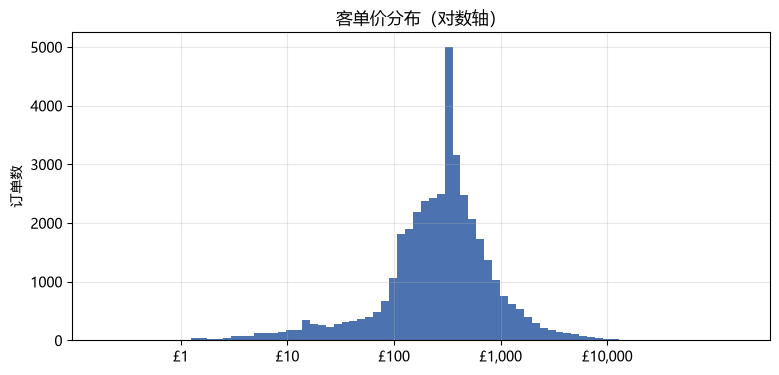

In [5]:
order_value = tx.groupby("Invoice")["Amount"].sum()
pct = order_value.quantile([0.25, 0.5, 0.75, 0.9, 0.99])
print(f"订单数 {len(order_value):,}，客单价 中位数 £{pct.loc[0.5]:.0f} | 均值 £{order_value.mean():.0f} | P99 £{pct.loc[0.99]:.0f}")

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(np.log10(order_value[order_value > 0]), bins=80, color="#4C72B0")
ax.set_xticks(range(0, 5), [f"£{10**k:,.0f}" for k in range(0, 5)])
ax.set_title("客单价分布（对数轴）")
ax.set_ylabel("订单数")
ax.grid(alpha=0.3)
fig.savefig(FIG / "04_aov_dist.png", dpi=120, bbox_inches="tight")
plt.show()

## 5. 头部商品与退货率

业务问题：**钱从哪些商品赚？退货集中在哪？**（退货率 = 退货件数 / 销出件数）

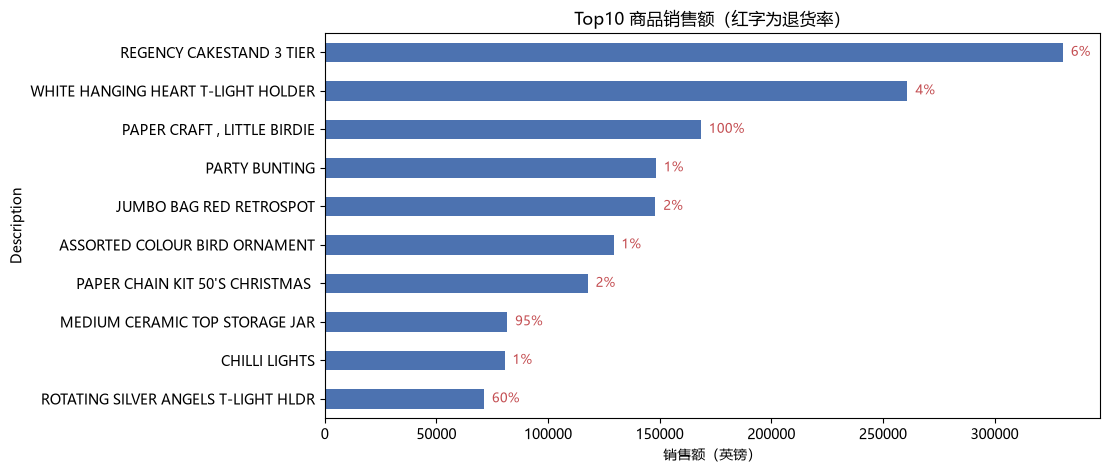

整体退货率（按件数）：4.4%


In [6]:
prod = tx[tx["is_product"]].groupby("Description").agg(revenue=("Amount", "sum"), units=("Quantity", "sum"))
ret_u = ret.dropna(subset=["Description"])
ret_u = ret_u.assign(units=ret_u["Quantity"].abs()).groupby("Description")["units"].sum().rename("units_returned")
top10 = prod.sort_values("revenue", ascending=False).head(10).join(ret_u).fillna(0)
top10["退货率"] = top10["units_returned"] / top10["units"]

fig, ax = plt.subplots(figsize=(10, 5))
top10["revenue"].sort_values().plot.barh(ax=ax, color="#4C72B0")
ax.set_title("Top10 商品销售额（红字为退货率）")
ax.set_xlabel("销售额（英镑）")
for i, name in enumerate(top10["revenue"].sort_values().index):
    ax.text(top10.loc[name, "revenue"], i, f"  {top10.loc[name, '退货率']:.0%}", va="center", fontsize=9, color="#C44E52")
fig.savefig(FIG / "05_top_products.png", dpi=120, bbox_inches="tight")
plt.show()

total_ret = ret["Quantity"].abs().sum() / tx[tx["is_product"]]["Quantity"].sum()
print(f"整体退货率（按件数）：{total_ret:.1%}")

## 6. RFM 客群分层

业务问题：**挽留券该发给谁？** 观察点取数据末日 +1 天（2011-12-10），对每个客户计算：
- **R**ecency：距最近一次购买的天数（越小越好）
- **F**requency：订单数
- **M**onetary：累计消费

两种方法对比：**分位数打分**（可解释、可给运营讲）vs **K-means**（肘部法+轮廓系数选 k，交叉验证分层结构）。频次有大量并列（很多客户只买 1 次），qcut 前先按 rank 打散。

In [7]:
snapshot = tx["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)
c = cust_tx.groupby("Customer_ID").agg(
    last_date=("InvoiceDate", "max"),
    Frequency=("Invoice", "nunique"),
    Monetary=("Amount", "sum"),
    first_date=("InvoiceDate", "min"),
    n_products=("StockCode", "nunique"),
)
c["Recency"] = (snapshot - c["last_date"]).dt.days
c["tenure"] = (c["last_date"] - c["first_date"]).dt.days
c["aov"] = c["Monetary"] / c["Frequency"]
print(f"客户数 {len(c):,}，观察点 {snapshot.date()}")
c[["Recency", "Frequency", "Monetary"]].describe().round(1)

客户数 5,878，观察点 2011-12-10


,Recency,Frequency,Monetary
count,5878.0,5878.0,5878.0
mean,200.9,6.3,2955.9
std,209.4,13.0,14440.9
min,0.0,1.0,3.0
25%,25.0,1.0,342.3
50%,95.0,3.0,867.7
75%,379.0,7.0,2248.3
max,738.0,398.0,580987.0


In [8]:
def score5(s, invert=False):
    """按 rank 分五档打分（1-5）；invert=True 时方向反转（Recency 越小分越高）"""
    labels = [1, 2, 3, 4, 5] if not invert else [5, 4, 3, 2, 1]
    return pd.qcut(s.rank(method="first"), 5, labels=labels).astype(int)

c["R_score"] = score5(c["Recency"], invert=True)
c["F_score"] = score5(c["Frequency"])
c["M_score"] = score5(c["Monetary"])

r, f = c["R_score"], c["F_score"]
c["segment"] = np.select(
    [(r >= 4) & (f >= 4), (r >= 3) & (f >= 3), r >= 4, (r <= 2) & (f >= 3)],
    ["重要价值客户", "忠诚客户", "潜力客户", "流失风险客户"],
    default="一般客户",
)
seg = c.groupby("segment").agg(
    人数=("Monetary", "size"), GMV=("Monetary", "sum"),
    R中位=("Recency", "median"), F中位=("Frequency", "median"), M中位=("Monetary", "median"),
)
seg["GMV占比"] = seg["GMV"] / seg["GMV"].sum()
seg["人数占比"] = seg["人数"] / seg["人数"].sum()
seg.sort_values("GMV", ascending=False).round(2)

,人数,GMV,R中位,F中位,M中位,GMV占比,人数占比
segment,,,,,,,
重要价值客户,1473,11994339.74,16.0,10.0,3397.82,0.69,0.25
忠诚客户,1230,2539717.74,72.0,4.0,1211.66,0.15,0.21
流失风险客户,824,1589703.32,373.0,4.0,1024.57,0.09,0.14
一般客户,1910,859021.90,400.0,1.0,296.30,0.05,0.32
潜力客户,441,392021.57,26.0,1.0,372.22,0.02,0.08


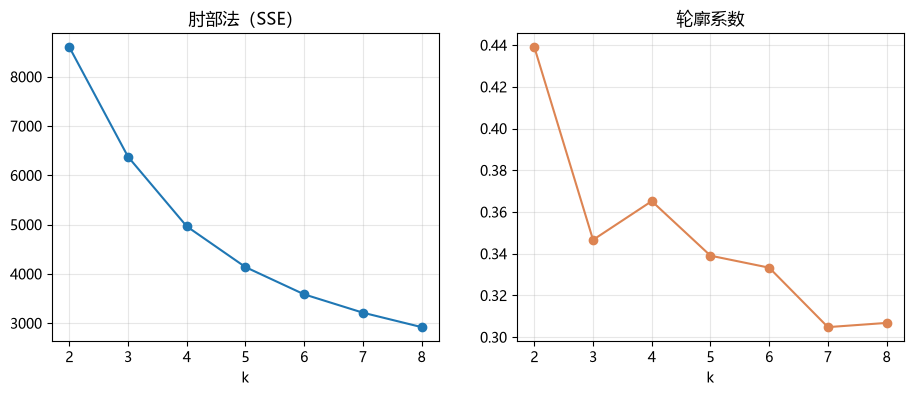

轮廓系数: {2: np.float64(0.439), 3: np.float64(0.347), 4: np.float64(0.365), 5: np.float64(0.339), 6: np.float64(0.333), 7: np.float64(0.305), 8: np.float64(0.307)}


In [9]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

X = StandardScaler().fit_transform(np.log1p(c[["Recency", "Frequency", "Monetary"]]))
ks, inertias, sils = range(2, 9), [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(X, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(ks, inertias, marker="o"); axes[0].set_title("肘部法（SSE）")
axes[1].plot(ks, sils, marker="o", color="#DD8452"); axes[1].set_title("轮廓系数")
for ax in axes: ax.set_xlabel("k"); ax.grid(alpha=0.3)
fig.savefig(FIG / "06_k_selection.png", dpi=120, bbox_inches="tight")
plt.show()
print("轮廓系数:", dict(zip(ks, np.round(sils, 3))))

In [10]:
km5 = KMeans(n_clusters=5, n_init=10, random_state=42).fit(X)
c["kmeans"] = km5.labels_
km_profile = c.groupby("kmeans").agg(
    人数=("Monetary", "size"), GMV=("Monetary", "sum"),
    R中位=("Recency", "median"), F中位=("Frequency", "median"), M中位=("Monetary", "median"),
)
km_profile["GMV占比"] = (km_profile["GMV"] / km_profile["GMV"].sum())
km_profile.sort_values("GMV", ascending=False).round(2)

,人数,GMV,R中位,F中位,M中位,GMV占比
kmeans,,,,,,
1,480,9552780.14,7.0,23.0,9323.61,0.55
4,1267,4763356.52,35.0,8.0,2909.86,0.27
3,1369,1844483.27,273.0,3.0,1037.28,0.11
2,1122,797350.70,25.0,2.0,635.04,0.05
0,1640,416833.63,411.0,1.0,228.65,0.02


分位数客群 × K-means 簇（行内占比）：
kmeans      0     1     2     3     4
segment                              
一般客户     0.78  0.00  0.05  0.17  0.00
忠诚客户     0.02  0.01  0.37  0.30  0.30
流失风险客户   0.12  0.00  0.00  0.82  0.06
潜力客户     0.06  0.00  0.94  0.00  0.00
重要价值客户   0.00  0.32  0.11  0.00  0.57


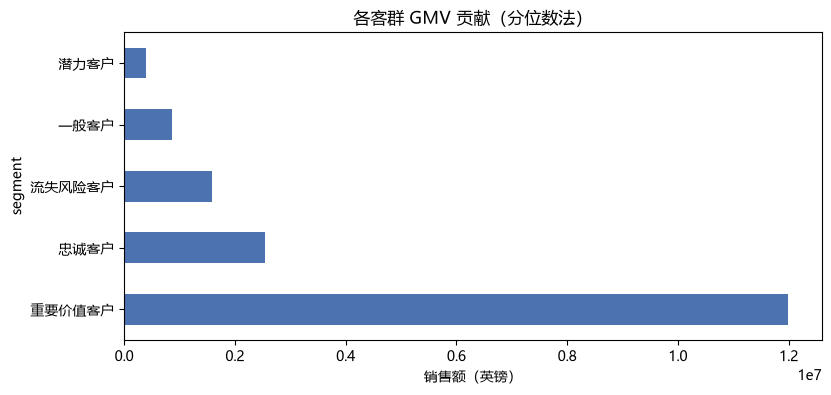


已保存 customers.parquet（5,878 位客户）


In [11]:
cross = pd.crosstab(c["segment"], c["kmeans"], normalize="index").round(2)
print("分位数客群 × K-means 簇（行内占比）：")
print(cross.to_string())

fig, ax = plt.subplots(figsize=(9, 4))
order = seg.sort_values("GMV", ascending=False).index
c.groupby("segment")["Monetary"].sum().reindex(order).plot.barh(ax=ax, color="#4C72B0")
ax.set_title("各客群 GMV 贡献（分位数法）")
ax.set_xlabel("销售额（英镑）")
fig.savefig(FIG / "07_segment_gmv.png", dpi=120, bbox_inches="tight")
plt.show()

c.reset_index().to_parquet(CLEAN / "customers.parquet", index=False)
print(f"\n已保存 customers.parquet（{len(c):,} 位客户）")

## 结论（2026-11-04 执行）

**三个核心发现：**

1. **增长引擎熄火**：GMV 同比仅 +1.9%（2010 年 1-11 月 £901 万 → 2011 年同期 £918 万），但新客从 2010 年的 3,387 人跌到 2011 年前 11 个月的 1,508 人（**-55%**）；2011-11 活跃客户中 88.5% 是老客——增长全靠存量撑着。

2. **二八定律极其陡峭**：25% 的"重要价值客户"（1,473 人）贡献 **69% GMV**；K-means 交叉验证更极端——8% 的客户（480 人）贡献 55%。同时各同期群次月平均留存仅 21.2%，新客承接质量在下滑。客单价中位 £302 vs 均值 £511，长尾显著（P99 £4,409）。

3. **挽留目标人群已锁定**：824 位"流失风险客户"（历史中位购买 4 次、合计贡献 9% GMV ≈ £159 万）已中位 373 天未回购。这是 03 流失预警模型要提前识别、04 报告要设计 A/B 挽留实验的人群——"券发给谁"由此从拍脑袋变成数据决策。

**方法说明**：最终采用分位数 RFM 打分（可向运营解释），K-means（k=5，肘部法+轮廓系数）作交叉验证，两法客群结构高度一致（流失风险客群 82% 单独成簇）。